# Stage 9 – Representative segment selection

**Purpose.** For each environment, choose a small set of **real recorded segments** that together
behave like all the driving in that environment. Stage 10 will join them into the driving cycle.

**Key rules (from the methodology).**
- Only **real segments** are used, with their original speed–time trace. A cluster centre is an average
  of numbers, not a drive, so it is never used as a trace.
- Every cluster from Stage 8 is represented **in proportion to its share of driving time**. Example: if
  congested traffic is 12 % of urban driving time, it gets 12 % of the urban cycle.
- **Complete ("good") segments are preferred**, because they start and end at rest (or at a steady
  cruise), so Stage 10 can join them without speed jumps.
- **Hold-out:** 30 % of the trips are set aside **before** any selection. They are never used to build a
  cycle and are kept for the independent validation in Stage 11.

**Two selection methods are compared (as the methodology asks).**
- **A. Nearest to the centre (medoid ranking):** take the most typical segments of each cluster.
- **B. Coverage:** step by step, add the segment that makes the selection's statistics closest to the
  statistics of the whole cluster.
The method whose selection reproduces its environment best is used.

**Output.** `intermediate/stage9_selected/selected_segments.csv` (the list) and `selected_traces.csv`
(their real 1 Hz speed traces), plus the trip split, cluster budgets, method comparison, figures and
verification in `outputs/stage9_selection/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
FEATURES = BASE / "intermediate/stage7_features/segment_features.csv"     # Stage 7: features per segment
CLUSTERS = BASE / "intermediate/stage8_clusters/segment_clusters.csv"     # Stage 8: cluster per segment
SEG_DIR = BASE / "intermediate/stage6_segmented"                          # Stage 6: 1 Hz data with seg_uid
OUT_DIR = BASE / "intermediate/stage9_selected"                           # selected segments + their speed traces
REPORT_DIR = BASE / "outputs/stage9_selection"                            # split, budgets, comparison, figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

for p in (FEATURES, CLUSTERS):
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Is Google Drive mounted, and have Stages 7 and 8 been run?")
seg = pd.read_csv(CLUSTERS).merge(
    pd.read_csv(FEATURES).drop(columns=["trip_id", "route", "environment", "quality"]), on="seg_uid", how="left")
print(f"{len(seg):,} clustered segments from {seg['trip_id'].nunique()} trips | "
      f"clusters: {seg.groupby('environment')['cluster_id'].nunique().to_dict()}")

1,021 clustered segments from 77 trips | clusters: {'Expressway': 3, 'Suburban': 3, 'Urban': 2}


In [2]:
CFG = {
    # --- hold-out: trips used for Stage 11 validation are never used to build a cycle
    "construction_share": 0.7,        # 70 % of the trips of each route build the cycles, 30 % are held out
    "random_state": 42,
    # --- target length of each environment's driving cycle (s)
    "target_duration_s": {"Urban": 1200, "Suburban": 600, "Expressway": 1800, "Intercity": 1200, "Rural": 1200},
    # --- which segments may be selected
    "prefer_quality": "good",         # complete segments (start/end at rest or at a steady-cruise cut); partial only as fallback
    "max_per_trip_per_cluster": 2,    # spread the selection over several trips (no single trip dominates a cluster)
    "typical_half": 0.5,              # the gap-filling step only uses the most typical 50 % of a cluster
    # --- statistics that a cycle must reproduce (time / distance weighted over all its segments)
    "stats": ["mean_speed_kmh", "idle_share", "cruise_share", "accel_share", "stops_per_km", "rpa_ms2", "std_accel_ms2"],
}
pd.Series(CFG, name="value").to_frame()

,value
construction_share,0.7
random_state,42
target_duration_s,"{'Urban': 1200, 'Suburban': 600, 'Expressway':..."
prefer_quality,good
max_per_trip_per_cluster,2
typical_half,0.5
stats,"[mean_speed_kmh, idle_share, cruise_share, acc..."


In [3]:
# Hold-out split by TRIP (never by segment: segments of one trip are not independent), stratified by route
trips = seg.groupby("trip_id")["route"].first().reset_index()
rng = np.random.default_rng(CFG["random_state"])
parts = []
for r, g in trips.groupby("route"):
    ids = rng.permutation(g["trip_id"].values)
    n_con = int(round(CFG["construction_share"] * len(ids)))
    parts.append(pd.DataFrame({"trip_id": ids, "route": r, "set": ["construction"] * n_con + ["held_out"] * (len(ids) - n_con)}))
split = pd.concat(parts).sort_values("trip_id").reset_index(drop=True)
split.to_csv(REPORT_DIR / "trip_split.csv", index=False)
seg = seg.merge(split[["trip_id", "set"]], on="trip_id")
con = seg[seg["set"] == "construction"].copy()
print("Trips per set and route:")
display(pd.crosstab(split["route"], split["set"], margins=True))
print("Construction segments per environment:", con["environment"].value_counts().to_dict())

Trips per set and route:


set,construction,held_out,All
route,,,
Route A,27,11,38
Route B,27,12,39
All,54,23,77


Construction segments per environment: {'Urban': 549, 'Expressway': 110, 'Suburban': 89}


In [4]:
def aggregate(rows):
    """Statistics of a SET of segments, as if they were driven one after another (time / distance weighted)."""
    T, D = rows["duration_s"].sum(), rows["distance_km"].sum()
    mov = rows["moving_s"].sum()
    return pd.Series({
        "duration_s": T, "distance_km": D, "segments": len(rows),
        "mean_speed_kmh": D / T * 3600 if T else np.nan,
        "idle_share": rows["stopped_s"].sum() / T if T else np.nan,
        "cruise_share": (rows["cruise_share"] * rows["duration_s"]).sum() / T if T else np.nan,
        "accel_share": (rows["accel_share"] * rows["duration_s"]).sum() / T if T else np.nan,
        "stops_per_km": rows["n_stops"].sum() / D if D else np.nan,
        "rpa_ms2": (rows["rpa_ms2"] * rows["distance_km"]).sum() / D if D else np.nan,
        "std_accel_ms2": np.sqrt((rows["std_accel_ms2"] ** 2 * rows["moving_s"]).sum() / mov) if mov else np.nan,
    })


def error(sel_stats, target, scale):
    """Mean of |selection - target| / scale over the statistics (scale = spread across segments, so units cancel)."""
    return float(np.mean([abs(sel_stats[s] - target[s]) / scale[s] for s in CFG["stats"]]))


def candidates(cl):
    """Selectable segments of one cluster: good ones first; partial ones only if good ones cannot fill the budget."""
    good = cl[cl["quality"] == CFG["prefer_quality"]]
    return good, cl[cl["quality"] != CFG["prefer_quality"]]


def select_nearest(cl, budget):
    """Method A (medoid ranking): take the most typical segments (closest to the cluster centre) until the budget is
    filled, then fill a remaining gap with the typical segment whose length fits best."""
    good, rest = candidates(cl)
    pool = pd.concat([good.sort_values("dist_to_centroid"), rest.sort_values("dist_to_centroid")])
    chosen, rem, per_trip = [], budget, {}
    for _, r in pool.iterrows():
        if rem <= 0:
            break
        if per_trip.get(r["trip_id"], 0) >= CFG["max_per_trip_per_cluster"]:
            continue
        if rem >= 0.5 * r["duration_s"]:                       # at least half of it fits
            chosen.append(r["seg_uid"]); rem -= r["duration_s"]
            per_trip[r["trip_id"]] = per_trip.get(r["trip_id"], 0) + 1
    if not chosen:                                             # budget smaller than every segment: take the most typical
        chosen.append(pool.iloc[0]["seg_uid"]); rem -= pool.iloc[0]["duration_s"]
    typical = pool[pool["dist_to_centroid"] <= pool["dist_to_centroid"].quantile(CFG["typical_half"])]
    if rem > 0.15 * budget:                                    # fill a large gap with the best-fitting typical segment
        fit = typical[~typical["seg_uid"].isin(chosen) & (typical["duration_s"] <= 1.5 * rem)]
        if len(fit):
            chosen.append(fit.loc[(fit["duration_s"] - rem).abs().idxmin(), "seg_uid"])
    return chosen


def select_coverage(cl, budget, target, scale):
    """Method B (coverage): greedily add the segment that brings the statistics of the selection closest to the
    statistics of the WHOLE cluster, until the budget is filled."""
    good, rest = candidates(cl)
    pool = good if good["duration_s"].sum() >= budget else pd.concat([good, rest])
    chosen, rem, per_trip = [], budget, {}
    while rem > 0:
        opts = pool[~pool["seg_uid"].isin(chosen)
                    & pool["trip_id"].map(lambda t: per_trip.get(t, 0) < CFG["max_per_trip_per_cluster"])
                    & ((pool["duration_s"] <= 1.5 * rem) | (len(chosen) == 0))]
        if not len(opts):
            break
        sel = pool[pool["seg_uid"].isin(chosen)]
        errs = [error(aggregate(pd.concat([sel, opts.loc[[i]]])), target, scale) for i in opts.index]
        best = opts.index[int(np.argmin(errs))]
        chosen.append(pool.at[best, "seg_uid"]); rem -= pool.at[best, "duration_s"]
        per_trip[pool.at[best, "trip_id"]] = per_trip.get(pool.at[best, "trip_id"], 0) + 1
    return chosen

In [5]:
order = ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]
envs = [e for e in order if e in set(con["environment"])]
budgets, picks = [], {"nearest (medoid)": [], "coverage": []}
for e in envs:
    E = con[con["environment"] == e]
    share = E.groupby("cluster_id")["duration_s"].sum() / E["duration_s"].sum()   # share of DRIVING TIME, not of segments
    for c, sh in share.items():
        cl = E[E["cluster_id"] == c]
        budget = CFG["target_duration_s"][e] * sh
        target = aggregate(cl)
        scale = cl[CFG["stats"]].std().replace(0, 1).fillna(1)
        budgets.append({"environment": e, "cluster_id": c, "time_share_%": round(100 * sh, 1),
                        "budget_s": round(budget), "candidates_good": int((cl["quality"] == "good").sum()),
                        "candidates_total": len(cl)})
        picks["nearest (medoid)"] += [(e, c, u) for u in select_nearest(cl, budget)]
        picks["coverage"] += [(e, c, u) for u in select_coverage(cl, budget, target, scale)]
budgets = pd.DataFrame(budgets)
budgets.to_csv(REPORT_DIR / "cluster_budgets.csv", index=False)
print("Time budget per cluster (cycle length x the cluster's share of driving time):")
budgets

Time budget per cluster (cycle length x the cluster's share of driving time):


,environment,cluster_id,time_share_%,budget_s,candidates_good,candidates_total
0,Urban,URB-C1,12.6,151,156,170
1,Urban,URB-C2,87.4,1049,271,379
2,Suburban,SUB-C1,10.9,65,2,14
3,Suburban,SUB-C2,68.5,411,0,48
4,Suburban,SUB-C3,20.6,123,2,27
5,Expressway,EXP-C1,4.6,83,0,24
6,Expressway,EXP-C2,2.8,50,0,24
7,Expressway,EXP-C3,92.6,1667,27,62


In [6]:
# Compare both methods: how well does each selection reproduce its environment (construction trips)?
rows = []
for m, lst in picks.items():
    chosen = pd.DataFrame(lst, columns=["environment", "cluster_id", "seg_uid"])
    for e in envs:
        E = con[con["environment"] == e]
        S = E[E["seg_uid"].isin(chosen.loc[chosen["environment"] == e, "seg_uid"])]
        tgt, sel = aggregate(E), aggregate(S)
        scale = E[CFG["stats"]].std().replace(0, 1).fillna(1)
        r = {"method": m, "environment": e, "selected_s": int(sel["duration_s"]), "target_s": CFG["target_duration_s"][e],
             "segments": int(sel["segments"]), "trips_used": S["trip_id"].nunique(),
             "partial_used": int((S["quality"] != "good").sum()), "mean_error": round(error(sel, tgt, scale), 3)}
        for s in CFG["stats"]:
            r[f"{s}_err_%"] = round(100 * (sel[s] - tgt[s]) / tgt[s], 1) if tgt[s] else np.nan
        rows.append(r)
method_cmp = pd.DataFrame(rows)
method_cmp.to_csv(REPORT_DIR / "method_comparison.csv", index=False)
mean_err = method_cmp.groupby("method")["mean_error"].mean()
METHOD = mean_err.idxmin()
print("Error of each selection vs. its environment (mean_error: lower = more representative; *_err_%: signed % difference)")
display(method_cmp)
print(f"Average error: {mean_err.round(3).to_dict()}  ->  selected method: {METHOD}")

Error of each selection vs. its environment (mean_error: lower = more representative; *_err_%: signed % difference)


,method,environment,selected_s,target_s,segments,trips_used,partial_used,mean_error,mean_speed_kmh_err_%,idle_share_err_%,cruise_share_err_%,accel_share_err_%,stops_per_km_err_%,rpa_ms2_err_%,std_accel_ms2_err_%
0,nearest (medoid),Urban,1271,1200,12,9,0,0.063,3.3,13.2,-4.8,1.3,18.8,-1.3,3.4
1,nearest (medoid),Suburban,590,600,10,9,6,0.128,-2.1,-32.5,10.2,0.4,-23.7,-17.8,-6.5
2,nearest (medoid),Expressway,1831,1800,5,4,3,0.122,-1.0,-10.5,-2.0,16.1,39.1,14.1,-11.1
3,coverage,Urban,1215,1200,11,10,0,0.022,-3.2,1.5,0.1,-0.4,12.1,-0.8,-0.6
4,coverage,Suburban,578,600,11,9,9,0.029,1.9,1.3,1.9,-1.3,4.8,-6.6,0.3
5,coverage,Expressway,1698,1800,4,4,2,0.060,0.5,6.4,1.5,-6.3,-1.6,0.7,8.9


Average error: {'coverage': 0.037, 'nearest (medoid)': 0.104}  ->  selected method: coverage


In [7]:
chosen = pd.DataFrame(picks[METHOD], columns=["environment", "cluster_id", "seg_uid"])
keep = ["seg_uid", "trip_id", "route", "environment", "cluster_id", "quality", "start_reason", "end_reason",
        "duration_s", "distance_km", "mean_speed_kmh", "max_speed_kmh", "idle_share", "n_stops", "dist_to_centroid", "silhouette"]
selected = chosen[["seg_uid"]].merge(con[keep], on="seg_uid")
selected["typicality_rank"] = selected["seg_uid"].map(
    con.assign(rk=con.groupby("cluster_id")["dist_to_centroid"].rank(method="first")).set_index("seg_uid")["rk"]).astype(int)
selected["method"] = METHOD
selected = selected.sort_values(["environment", "cluster_id", "typicality_rank"]).reset_index(drop=True)
selected.to_csv(OUT_DIR / "selected_segments.csv", index=False)

# speed traces of the selected segments, exactly as recorded (chronological, 1 Hz, unchanged)
traces = []
for tid, g in selected.groupby("trip_id"):
    d = pd.read_csv(SEG_DIR / f"{tid}.csv", usecols=["seg_uid", "t_s", "speed_kmh", "speed_flag", "environment"])
    d = d[d["seg_uid"].isin(g["seg_uid"])].copy()
    d["t_in_segment_s"] = d.groupby("seg_uid")["t_s"].transform(lambda t: t - t.min())
    traces.append(d)
traces = pd.concat(traces).sort_values(["seg_uid", "t_s"]).reset_index(drop=True)
traces.to_csv(OUT_DIR / "selected_traces.csv", index=False)

summary = selected.groupby(["environment", "cluster_id"]).agg(
    segments=("seg_uid", "count"), selected_s=("duration_s", "sum"), trips=("trip_id", "nunique"),
    partial=("quality", lambda q: int((q != "good").sum())), median_typicality_rank=("typicality_rank", "median"))
summary = summary.join(budgets.set_index(["environment", "cluster_id"])[["time_share_%", "budget_s"]])
summary["selected_share_%"] = (100 * summary["selected_s"] / summary.groupby(level=0)["selected_s"].transform("sum")).round(1)
summary.to_csv(REPORT_DIR / "selection_summary.csv")
print(f"Selected with '{METHOD}': {len(selected)} segments, {traces['seg_uid'].nunique()} speed traces "
      f"({len(traces):,} seconds)")
summary

Selected with 'coverage': 26 segments, 26 speed traces (3,491 seconds)


segments  selected_s  trips  partial  median_typicality_rank  time_share_%  budget_s  selected_share_%
environment cluster_id                                                                                                        
Expressway  EXP-C1             1          78      1        1                     6.0           4.6        83               4.6
            EXP-C2             1          50      1        1                     2.0           2.8        50               2.9
            EXP-C3             2        1570      2        0                    27.5          92.6      1667              92.5
Suburban    SUB-C1             2          67      1        0                     8.5          10.9        65              11.6
            SUB-C2             6         394      5        6                    12.5          68.5       411              68.2
            SUB-C3             3         117      3        3                     4.0          20.6       123              20.2
Urban       URB-C1             3         154      3        0                    11.0          12.6       151              12.7
            URB-C2             8        1061      7        0                   124.5          87.4      1049              87.3

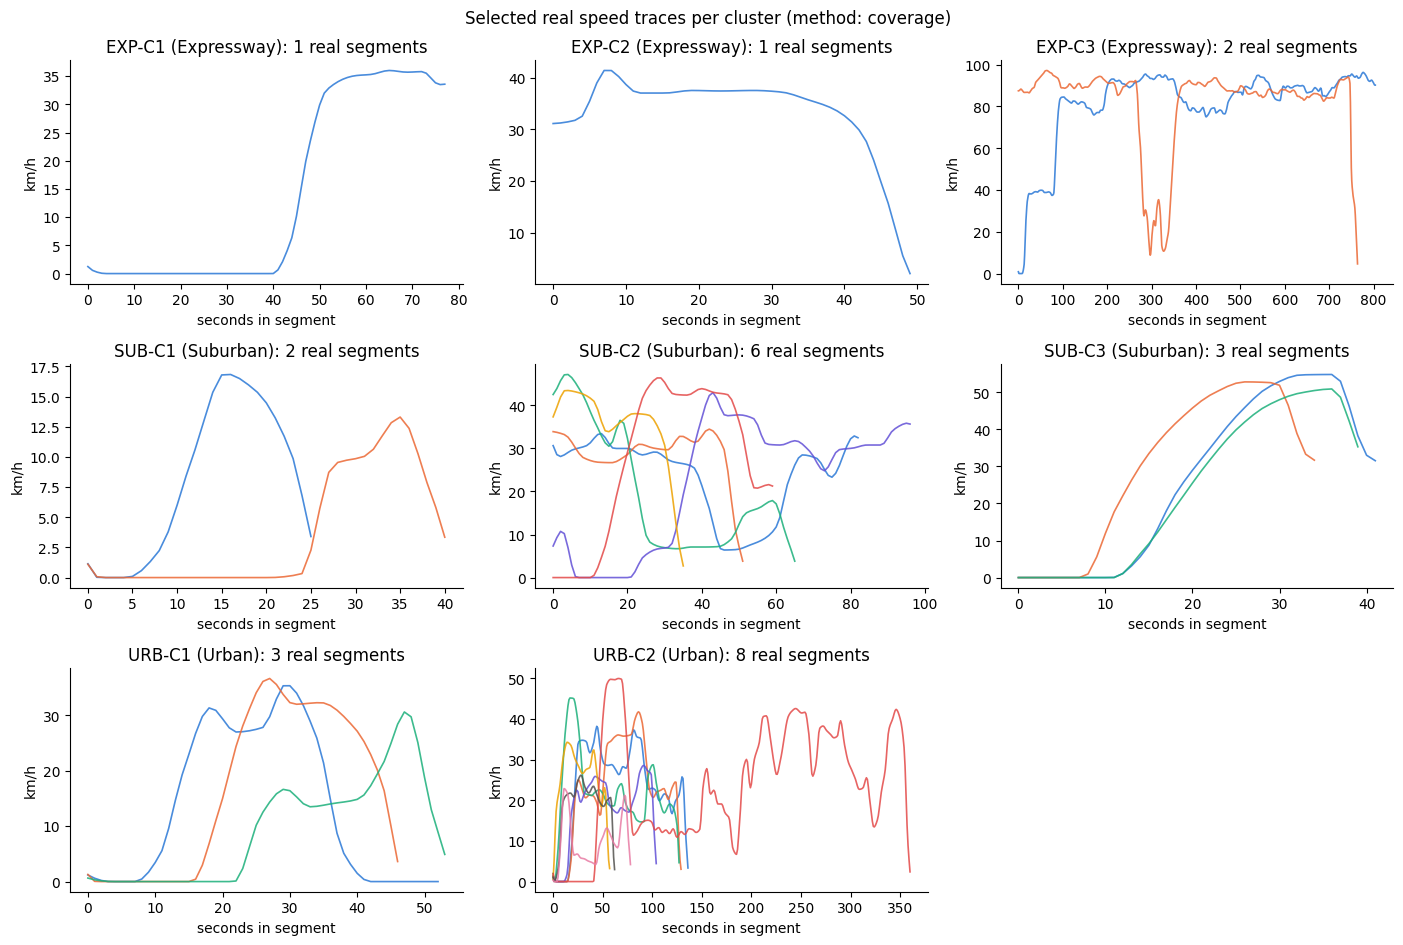

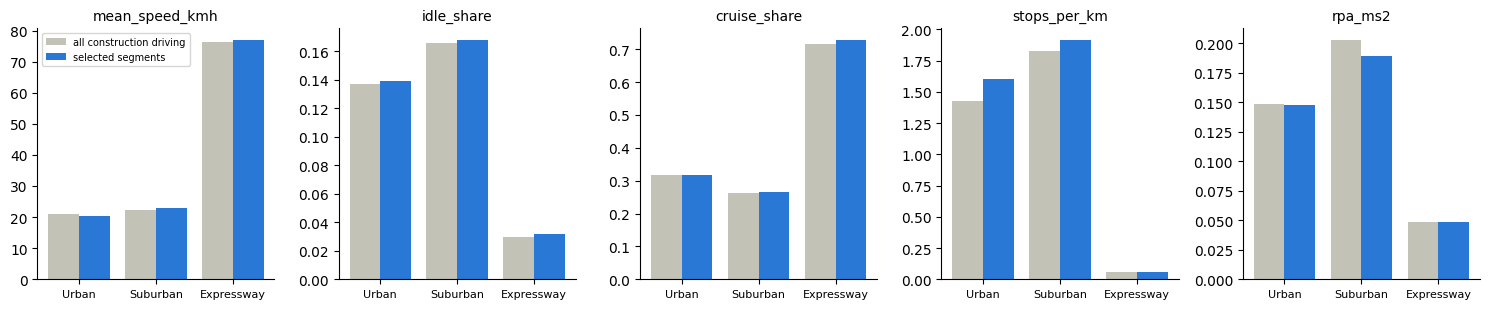

In [8]:
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100", "#e34948", "#52514e", "#e87ba4"]
cl_list = selected[["environment", "cluster_id"]].drop_duplicates().values.tolist()
ncol = 3
nrow = int(np.ceil(len(cl_list) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.2 * nrow), squeeze=False)
for ax, (e, c) in zip(axes.ravel(), cl_list):
    ids = selected.loc[selected["cluster_id"] == c, "seg_uid"]
    for i, u in enumerate(ids):
        t = traces[traces["seg_uid"] == u]
        ax.plot(t["t_in_segment_s"], t["speed_kmh"], lw=1.2, color=palette[i % len(palette)], alpha=0.85)
    ax.set(title=f"{c} ({e}): {len(ids)} real segments", xlabel="seconds in segment", ylabel="km/h")
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.ravel()[len(cl_list):]:
    ax.axis("off")
fig.suptitle(f"Selected real speed traces per cluster (method: {METHOD})", fontsize=12)
plt.tight_layout()
plt.savefig(REPORT_DIR / "selected_traces.png", dpi=150)
plt.show()

stats_show = ["mean_speed_kmh", "idle_share", "cruise_share", "stops_per_km", "rpa_ms2"]
fig, axes = plt.subplots(1, len(stats_show), figsize=(15, 3.2))
for ax, s in zip(axes, stats_show):
    tg = [aggregate(con[con["environment"] == e])[s] for e in envs]
    sl = [aggregate(con[con["seg_uid"].isin(selected.loc[selected["environment"] == e, "seg_uid"])])[s] for e in envs]
    x = np.arange(len(envs))
    ax.bar(x - 0.2, tg, 0.4, color="#c3c2b7", label="all construction driving")
    ax.bar(x + 0.2, sl, 0.4, color="#2a78d6", label="selected segments")
    ax.set_xticks(x, envs, fontsize=8)
    ax.set_title(s, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(REPORT_DIR / "selection_vs_target.png", dpi=150)
plt.show()

In [9]:
checks = {}
held = set(split.loc[split["set"] == "held_out", "trip_id"])
checks["no selected segment comes from a held-out trip"] = not (set(selected["trip_id"]) & held)
checks["hold-out split by trip (no trip in both sets)"] = split["trip_id"].is_unique
checks["no segment selected twice"] = selected["seg_uid"].is_unique
checks["every cluster is represented by >= 1 real segment"] = set(budgets["cluster_id"]) <= set(selected["cluster_id"])
checks[f"at most {CFG['max_per_trip_per_cluster']} segments per trip per cluster"] = bool(
    selected.groupby(["cluster_id", "trip_id"]).size().max() <= CFG["max_per_trip_per_cluster"])
tot = selected.groupby("environment")["duration_s"].sum()
checks["selected length within +/-25 % of the target cycle length"] = bool(
    all(abs(tot[e] - CFG["target_duration_s"][e]) <= 0.25 * CFG["target_duration_s"][e] for e in envs))
checks["cluster time shares kept (within 15 percentage points)"] = bool(
    (summary["selected_share_%"] - summary["time_share_%"]).abs().max() <= 15)
# traces must be the recorded data, unchanged and in order
ok = []
for u, t in traces.groupby("seg_uid"):
    r = selected.set_index("seg_uid").loc[u]
    ok.append(len(t) == r["duration_s"] and bool((np.diff(t["t_s"].values) == 1).all())
              and abs(t["speed_kmh"].mean() - r["mean_speed_kmh"]) < 1e-3 and t["speed_kmh"].notna().all())
checks["traces = recorded speed (1 s steps, complete, same mean as Stage 7)"] = all(ok) and len(ok) == len(selected)
checks["cluster centre never used as a trace (only real segments)"] = set(traces["seg_uid"]) == set(selected["seg_uid"])
verification = pd.DataFrame({"result": ["PASS" if v else "CHECK" for v in checks.values()]}, index=checks.keys())
verification

,result
no selected segment comes from a held-out trip,PASS
hold-out split by trip (no trip in both sets),PASS
no segment selected twice,PASS
every cluster is represented by >= 1 real segment,PASS
at most 2 segments per trip per cluster,PASS
selected length within +/-25 % of the target cycle length,PASS
cluster time shares kept (within 15 percentage points),PASS
"traces = recorded speed (1 s steps, complete, same mean as Stage 7)",PASS
cluster centre never used as a trace (only real segments),PASS


In [10]:
print("STAGE 9 – REPRESENTATIVE SEGMENT SELECTION: KEY RESULTS")
print("-" * 60)
print(f"Hold-out: {(split['set'] == 'construction').sum()} construction trips, {(split['set'] == 'held_out').sum()} held-out trips "
      "(held-out trips are kept for Stage 11 validation)")
print(f"Method compared: nearest-to-centre (medoid) vs coverage -> selected: {METHOD} "
      f"(average error {mean_err[METHOD]:.3f} vs {mean_err.drop(METHOD).iloc[0]:.3f})")
mc = method_cmp[method_cmp["method"] == METHOD].set_index("environment")
for e in envs:
    r = mc.loc[e]
    print(f"  {e:10s}: {int(r['segments']):3d} real segments from {int(r['trips_used'])} trips, {int(r['selected_s'])} s "
          f"(target {int(r['target_s'])} s) | mean speed error {r['mean_speed_kmh_err_%']:+.1f} %, "
          f"idle error {r['idle_share_err_%']:+.1f} %, stops/km error {r['stops_per_km_err_%']:+.1f} %")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 9 – REPRESENTATIVE SEGMENT SELECTION: KEY RESULTS
------------------------------------------------------------
Hold-out: 54 construction trips, 23 held-out trips (held-out trips are kept for Stage 11 validation)
Method compared: nearest-to-centre (medoid) vs coverage -> selected: coverage (average error 0.037 vs 0.104)
  Urban     :  11 real segments from 10 trips, 1215 s (target 1200 s) | mean speed error -3.2 %, idle error +1.5 %, stops/km error +12.1 %
  Suburban  :  11 real segments from 9 trips, 578 s (target 600 s) | mean speed error +1.9 %, idle error +1.3 %, stops/km error +4.8 %
  Expressway:   4 real segments from 4 trips, 1698 s (target 1800 s) | mean speed error +0.5 %, idle error +6.4 %, stops/km error -1.6 %
Verification: all checks PASS
